In [1]:
%load_ext autoreload
%autoreload 2

In [1]:
import pandas as pd
import os
import glob
import shutil
import geopandas as gpd

import xarray as xr
import numpy as np
from pyhomogenize import open_xrdataset
import seaborn as sns
#
import matplotlib as mpl
import matplotlib.pyplot as plt
import cftime
import xesmf as xe
import cordex as cx

In [2]:
from colors_indices import colorsteps_diff, colorsteps_absolute, colorsteps_exposure
from plotting_tools_africa import plot_absolut
from plotting_shape_file import min_max_levels, mask_and_save, maskout_country
from regrid_afr22 import regrid_ensemble_median, regrid_ensemble
from calculate_diff_robustness import timeslice, ensemblemean_exp
from format_compound_event_tools import annual_sum_with_carry_grid_fast

In [3]:
# The data needs to be regridded to the AFR-22 domain.
# Target Grid::
dm=cx.cordex_domain('AFR-22', bounds=True)

In [4]:
# Directory input data: calculated compound events
datadir='/work/ch0636/g300047/cicles/compound-events/results'
#outdatadir='/work/ch0636/g300047/cicles/compound-events/results/annual_ev_coin_du'
outdatadir='/work/ch0636/g300047/cicles/compound-events/results/annual_test'
#Variable in compound event file:
var='ev_coin_du'


In [5]:
# Make desision what you want to plot: 
#var_pattern='SU40_du3_TR26_du3'
#title="Ensemble Median of Concurrent Heatwave [Tmax>40°C] and Tropical Night [Tmin>26°C]\nEvents Lasting at Least 3 Days"
#var_pattern='SU_du3_DD_du5'
#title="Ensemble Median of Concurrent Heatwave [Tmax>35°C] and Dry Days [RR<1mm/day]\nEvents Lasting at Least 3 and 5 Days"
#no:
#var_pattern='SU35_du3_R20mm_du1'
#title="Ensemble Median of Concurrent Heatwave [Tmax>35°C] and Heavy Precipitation Event [RR>20mm/day]\nEvents Lasting at Least 3 and 1 Days"
var_pattern='SU40_du3_DD_du5'
title="Ensemble Median of Concurrent Heatwave [Tmax>40°C] and Dry Days [RR<1mm/day]\nEvents Lasting at Least 3 and 5 Days"
#var_pattern='SU40_du3_R20mm_du1'
#title="Ensemble Median of Concurrent Heatwave [Tmax>40°C] and Heavy Precipitation Event [RR>20mm/day]\nEvents Lasting at Least 3 and 1 Days"
#var_pattern='SU40_du3_R50mm_du1'
#title="Ensemble Median of Concurrent Heatwave [Tmax>40°C] and Heavy Precipitation Event [RR>50mm/day]\nEvents Lasting at Least 3 and 1 Days"
#var_pattern='SU40_du3_TR_du3'
#title="Ensemble Median of Concurrent Heatwave [Tmax>40°C] and Tropical Night [Tmin>20°C]\nEvents Lasting at Least 3 Days"

In [6]:
# openfile
pattern='SU40_du3_DD_du5_AFR-22_MOHC-HadGEM2-ES_rcp26_r1i1p1_GERICS-REMO2015'
#files=glob.glob(os.path.join(datadir, f"compev_{var_pattern}_AFR-22_*.nc"))
files=glob.glob(os.path.join(datadir, f"compev_{pattern}_*.nc"))
for f in files:
    print(f)
    #coin_ds=xr.open_dataset(f, decode_times=False)
    coin_ds=open_xrdataset(f, decode_times=False)
    coin_ds
    # Re-run
    outfile=os.path.basename(f).replace(".nc", "_annual.nc")
    outfile_grid = os.path.join(outdatadir, outfile)
    ds_out = annual_sum_with_carry_grid_fast(coin_ds, outfile_grid)
    
    print(f"Updated with date dimension: {outfile_grid}")
    

/work/ch0636/g300047/cicles/compound-events/results/compev_SU40_du3_DD_du5_AFR-22_MOHC-HadGEM2-ES_rcp26_r1i1p1_GERICS-REMO2015_v1_day_GERICS_2069-2098.nc
Updated with date dimension: /work/ch0636/g300047/cicles/compound-events/results/annual_test/compev_SU40_du3_DD_du5_AFR-22_MOHC-HadGEM2-ES_rcp26_r1i1p1_GERICS-REMO2015_v1_day_GERICS_2069-2098_annual.nc
/work/ch0636/g300047/cicles/compound-events/results/compev_SU40_du3_DD_du5_AFR-22_MOHC-HadGEM2-ES_rcp26_r1i1p1_GERICS-REMO2015_v1_day_GERICS_2031-2060.nc
Updated with date dimension: /work/ch0636/g300047/cicles/compound-events/results/annual_test/compev_SU40_du3_DD_du5_AFR-22_MOHC-HadGEM2-ES_rcp26_r1i1p1_GERICS-REMO2015_v1_day_GERICS_2031-2060_annual.nc
/work/ch0636/g300047/cicles/compound-events/results/compev_SU40_du3_DD_du5_AFR-22_MOHC-HadGEM2-ES_rcp26_r1i1p1_GERICS-REMO2015_v1_day_GERICS_1991-2020.nc
Updated with date dimension: /work/ch0636/g300047/cicles/compound-events/results/annual_test/compev_SU40_du3_DD_du5_AFR-22_MOHC-HadGEM

In [7]:
coin_ds

<xarray.Dataset> Size: 69GB
Dimensions:          (time: 10800, rlat: 417, rlon: 385, vertices: 4)
Coordinates:
  * time             (time) object 86kB 1991-01-01 12:00:00 ... 2020-12-30 12...
  * rlon             (rlon) float64 3kB -24.53 -24.31 -24.09 ... 59.73 59.95
  * rlat             (rlat) float64 3kB -47.63 -47.41 -47.19 ... 43.67 43.89
Dimensions without coordinates: vertices
Data variables: (12/26)
    lon              (rlat, rlon) float32 642kB dask.array<chunksize=(417, 385), meta=np.ndarray>
    lon_bnds         (rlat, rlon, vertices) float32 3MB dask.array<chunksize=(417, 385, 4), meta=np.ndarray>
    lat              (rlat, rlon) float32 642kB dask.array<chunksize=(417, 385), meta=np.ndarray>
    lat_bnds         (rlat, rlon, vertices) float32 3MB dask.array<chunksize=(417, 385, 4), meta=np.ndarray>
    height           float64 8B ...
    ev_data          (time, rlat, rlon) float32 7GB dask.array<chunksize=(1, 417, 385), meta=np.ndarray>
    ...               ...
    ev_br_2af1_sdu2  (rlat, rlon) float32 642kB dask.array<chunksize=(417, 385), meta=np.ndarray>
    n_ev_2af1        (rlat, rlon) float32 642kB dask.array<chunksize=(417, 385), meta=np.ndarray>
    ev_2af1_du1      (time, rlat, rlon) float32 7GB dask.array<chunksize=(1, 417, 385), meta=np.ndarray>
    ev_2af1_du2      (time, rlat, rlon) float32 7GB dask.array<chunksize=(1, 417, 385), meta=np.ndarray>
    ev_2af1_sdu1     (rlat, rlon) float32 642kB dask.array<chunksize=(417, 385), meta=np.ndarray>
    ev_2af1_sdu2     (rlat, rlon) float32 642kB dask.array<chunksize=(417, 385), meta=np.ndarray>
Attributes: (12/48)
    CDI:                            Climate Data Interface version 2.2.4 (htt...
    Conventions:                    CF-1.4
    source:                         GERICS-REMO2015
    institution:                    Helmholtz-Zentrum Geesthacht, Climate Ser...
    history:                        Thu Jul 31 14:57:41 2025: cdo selyear,199...
    institute_id:                   GERICS
    ...                             ...
    ci_frequency:                   day
    ci_timerange_source:            19700101-20991230
    ci_package_name:                xclim_0.57.0
    ci_package_reference:           xcalc_0.12.0
    ci_timerange_index:             19700101-19701230
    CDO:                            Climate Data Operators version 2.2.2 (htt...

In [22]:
outdatadir

'/work/ch0636/g300047/cicles/compound-events/results/annual_test'

In [23]:
# REGRID all simulations to the same grid
# regridded files are saved

weights_dir = os.path.join(datadir, "weights")
os.makedirs(weights_dir, exist_ok=True)

# Use all annual files created in outdatadir (not just one outfile_grid)
annual_files = sorted(
	glob.glob(os.path.join(outdatadir, f"compev_{var_pattern}_AFR-22_*_annual.nc"))
)

if not annual_files:
	raise FileNotFoundError(
		f"No annual files found in {outdatadir} for pattern 'compev_{var_pattern}_AFR-22_*_annual.nc'"
	)

regrid_ensemble(annual_files, dm, weights_dir, weightvar="ev_coin_du_days")
        


Regridding: compev_SU35_du3_DD_du5_AFR-22_MOHC-HadGEM2-ES_rcp26_r1i1p1_GERICS-REMO2015_v1_day_GERICS_1991-2020_annual.nc
weight_file:  /work/ch0636/g300047/cicles/compound-events/results/weights/w_compev_SU35_du3_DD_du5_AFR-22_MOHC-HadGEM2-ES_rcp26_r1i1p1_GERICS-REMO2015_v1_day_GERICS_1991-2020_annual_to_AFR22_bilinear.nc
FrozenMappingWarningOnValuesAccess({'rlat': 417, 'rlon': 385, 'time': 30, 'vertices': 4}) ['rlat', 'rlon', 'time', 'lat', 'lon']
FrozenMappingWarningOnValuesAccess({'rlon': 388, 'rlat': 402, 'vertices': 4}) ['rlon', 'rlat', 'lon', 'lat', 'lon_vertices', 'lat_vertices']
  exists: True
  Saved regridded data to: /work/ch0636/g300047/cicles/compound-events/results/weights/compev_SU35_du3_DD_du5_AFR-22_MOHC-HadGEM2-ES_rcp26_r1i1p1_GERICS-REMO2015_v1_day_GERICS_1991-2020_annual_regridded_AFR22.nc
Regridding: compev_SU35_du3_DD_du5_AFR-22_MOHC-HadGEM2-ES_rcp26_r1i1p1_GERICS-REMO2015_v1_day_GERICS_2031-2060_annual.nc
weight_file:  /work/ch0636/g300047/cicles/compound-events/

In [17]:
weights_dir

'/work/ch0636/g300047/cicles/compound-events/results/weights'

In [26]:
import os
import numpy as np
import pandas as pd
import xarray as xr

try:
    import numba as nb
    _HAS_NUMBA = True
except ModuleNotFoundError:
    _HAS_NUMBA = False


if _HAS_NUMBA:
    @nb.njit(parallel=True, fastmath=True)
    def _annual_sum_with_carry_3d(arr, start_year_idx, days_left_start, year_lengths):
        # arr: (time, rlat, rlon)
        nt, ny, nx = arr.shape
        nyears = len(year_lengths)
        out = np.zeros((nyears, ny, nx), dtype=np.float32)

        for j in nb.prange(ny):
            for i in range(nx):
                for t in range(nt):
                    v = arr[t, j, i]
                    if not np.isfinite(v) or v <= 0:
                        continue

                    rem = v
                    yi = start_year_idx[t]

                    add = rem if rem < days_left_start[t] else days_left_start[t]
                    out[yi, j, i] += add
                    rem -= add
                    yi += 1

                    while rem > 0 and yi < nyears:
                        yl = year_lengths[yi]
                        add = rem if rem < yl else yl
                        out[yi, j, i] += add
                        rem -= add
                        yi += 1
        return out
else:
    def _annual_sum_with_carry_3d(arr, start_year_idx, days_left_start, year_lengths):
        # arr: (time, rlat, rlon)
        nt, ny, nx = arr.shape
        nyears = len(year_lengths)
        out = np.zeros((nyears, ny, nx), dtype=np.float32)

        for j in range(ny):
            for i in range(nx):
                for t in range(nt):
                    v = arr[t, j, i]
                    if not np.isfinite(v) or v <= 0:
                        continue

                    rem = v
                    yi = int(start_year_idx[t])

                    add = rem if rem < days_left_start[t] else days_left_start[t]
                    out[yi, j, i] += add
                    rem -= add
                    yi += 1

                    while rem > 0 and yi < nyears:
                        yl = year_lengths[yi]
                        add = rem if rem < yl else yl
                        out[yi, j, i] += add
                        rem -= add
                        yi += 1
        return out


# --- calendar-aware helpers ---
def _is_leap_year(year, calendar="standard"):
    cal = str(calendar).lower()
    if cal in ("noleap", "365_day", "360_day"):
        return False
    if cal in ("all_leap", "366_day"):
        return True
    if cal == "julian":
        return year % 4 == 0
    return (year % 4 == 0) and ((year % 100 != 0) or (year % 400 == 0))


def _days_in_year(year, calendar="standard"):
    cal = str(calendar).lower()
    if cal == "360_day":
        return 360
    if cal in ("noleap", "365_day"):
        return 365
    if cal in ("all_leap", "366_day"):
        return 366
    return 366 if _is_leap_year(year, cal) else 365


def _extract_year_doy(d):
    """Return (year, day_of_year) for cftime, datetime, pandas, or numpy datetime64."""
    if hasattr(d, "year"):
        year = int(d.year)
        if hasattr(d, "dayofyr"):
            return year, int(d.dayofyr)
        return year, int(d.timetuple().tm_yday)

    ts = pd.Timestamp(d)
    return int(ts.year), int(ts.dayofyear)


def annual_sum_with_carry_grid_fast(da, outfile, out_var_name="ev_coin_du_days", dates=None):
    if "time" not in da.dims:
        raise ValueError("Input DataArray must have a 'time' dimension.")

    time_calendar = (
        da["time"].attrs.get("calendar")
        or da["time"].encoding.get("calendar")
        or "standard"
    )

    if dates is None:
        time_values = da["time"].values
        if np.issubdtype(np.asarray(time_values).dtype, np.number):
            time_units = da["time"].attrs.get("units", da["time"].encoding.get("units", None))
            if time_units is None:
                raise ValueError("Numeric time axis found, but no time units available in attrs/encoding.")
            dates = xr.coding.times.decode_cf_datetime(
                time_values,
                units=time_units,
                calendar=time_calendar,
            )
        else:
            # Keep native index values (works for DatetimeIndex and CFTimeIndex)
            idx = da.indexes.get("time", None)
            if idx is not None:
                dates = np.asarray(idx.values)
            else:
                dates = np.asarray(time_values)

    if len(dates) != da.sizes["time"]:
        raise ValueError("Length of 'dates' must match size of da.time.")

    year_doy = np.array([_extract_year_doy(d) for d in dates], dtype=np.int32)
    years = year_doy[:, 0]
    doy = year_doy[:, 1].astype(np.int16)

    unique_years = np.unique(years)
    year_to_idx = {y: i for i, y in enumerate(unique_years)}
    start_year_idx = np.array([year_to_idx[y] for y in years], dtype=np.int32)

    year_lengths = np.array([_days_in_year(int(y), time_calendar) for y in unique_years], dtype=np.float32)
    days_left_start = (year_lengths[start_year_idx] - doy + 1).astype(np.float32)

    da_t = da.transpose("time", "rlat", "rlon")
    arr = np.asarray(da_t.values, dtype=np.float32)

    out = _annual_sum_with_carry_3d(arr, start_year_idx, days_left_start, year_lengths)

    annual_da = xr.DataArray(
        out,
        dims=("year", "rlat", "rlon"),
        coords={"year": unique_years, "rlat": da_t["rlat"], "rlon": da_t["rlon"]},
        name=out_var_name,
        attrs={
            "long_name": "annual sum of ev_coin_du with cross-year carry-over",
            "units": "days",
            "calendar": time_calendar,
        },
    )

    ds_out = annual_da.to_dataset()

    try:
        ds_out.to_netcdf(
            outfile,
            engine="netcdf4",
            encoding={out_var_name: {"zlib": True, "complevel": 4, "dtype": "float32"}},
        )
    except Exception:
        ds_out.to_netcdf(outfile)

    return ds_out


# Re-run
outfile_grid = os.path.join(outdatadir, f"annual_sum_with_carry_{var_pattern}_fullgrid_3.nc")
annual_grid_ds = annual_sum_with_carry_grid_fast(dforg["ev_coin_du"], outfile_grid)

# Convert dimension from "year" to "date" and write to NetCDF
cal = annual_grid_ds["ev_coin_du_days"].attrs.get("calendar", "standard")
cal_lower = str(cal).lower()
years = annual_grid_ds["year"].values.astype(int)

if cal_lower in {"standard", "gregorian", "proleptic_gregorian", "julian"}:
    date_vals = pd.to_datetime([f"{y}-01-01" for y in years])
else:
    # Use fixed-width string dtype (object dtype can fail when writing NetCDF)
    date_vals = np.array([f"{y}-01-01" for y in years], dtype="U10")

# Rename dimension and assign date as the dimension coordinate
annual_grid_ds = annual_grid_ds.rename({"year": "date"})
annual_grid_ds = annual_grid_ds.assign_coords(date=("date", date_vals), year=("date", years))
annual_grid_ds["date"].attrs["long_name"] = "start date of accumulation year"
annual_grid_ds["year"].attrs["long_name"] = "calendar year"

# Avoid encoding conflicts with CF datetime encoder
annual_grid_ds["date"].attrs.pop("calendar", None)
annual_grid_ds["date"].attrs.pop("units", None)

# Explicit, safe write
if np.issubdtype(annual_grid_ds["date"].dtype, np.datetime64):
    annual_grid_ds["date"].encoding = {
        "units": "days since 1900-01-01",
        "calendar": "proleptic_gregorian" if cal_lower == "standard" else cal_lower,
    }

annual_grid_ds.to_netcdf(outfile_grid, mode="w", engine="netcdf4")
print(f"Updated with date dimension: {outfile_grid}")


Updated with date dimension: /work/ch0636/g300047/cicles/compound-events/results/diff_robustness/annual_sum_with_carry_SU35_du3_DD_du5_fullgrid_3.nc


In [24]:
test=xr.open_dataset(outfile_grid, decode_times=False)  
test

<xarray.Dataset> Size: 19MB
Dimensions:          (year: 30, rlat: 417, rlon: 385)
Coordinates:
  * year             (year) int32 120B 2069 2070 2071 2072 ... 2096 2097 2098
  * rlat             (rlat) float64 3kB -47.63 -47.41 -47.19 ... 43.67 43.89
  * rlon             (rlon) float64 3kB -24.53 -24.31 -24.09 ... 59.73 59.95
    date             (year) int64 240B ...
Data variables:
    ev_coin_du_days  (year, rlat, rlon) float32 19MB ...

/tmp/ipykernel_522315/229684060.py:1: FutureWarning: In a future version, xarray will not decode timedelta values based on the presence of a timedelta-like units attribute by default. Instead it will rely on the presence of a timedelta64 dtype attribute, which is now xarray's default way of encoding timedelta64 values. To continue decoding timedeltas based on the presence of a timedelta-like units attribute, users will need to explicitly opt-in by passing True or CFTimedeltaCoder(decode_via_units=True) to decode_timedelta. To silence this warning, set decode_timedelta to True, False, or a 'CFTimedeltaCoder' instance.
  look = xr.open_dataset(outfile_grid)


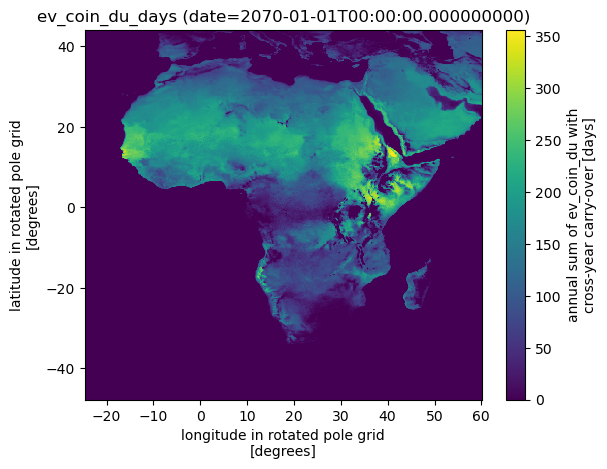

In [ ]:
look = xr.open_dataset(outfile_grid)

# new dimension is "time"
da_plot = look["ev_coin_du_days"].isel(time=1)
if np.issubdtype(da_plot.dtype, np.timedelta64):
    da_plot = da_plot / np.timedelta64(1, "D")
    da_plot.attrs["units"] = "days"

da_plot.plot()
plt.title(f"ev_coin_du_days (time={str(look.time.isel(time=1).values)})")
plt.show()

In [ ]:
# now check if sum over time matches the total sum of ev_coin_du in the original dataset
total_sum = look["ev_coin_du_days"].sum(dim="time")

# convert timedelta to numeric days if needed
if np.issubdtype(total_sum.dtype, np.timedelta64):
    total_sum = total_sum / np.timedelta64(1, "D")

#original_sum = dforg["ev_coin_du"].sum(dim="time")
original_sum = dforg["ev_coin_sdu"]

diff = total_sum - original_sum
diff
print(f"Total sum over time: {total_sum.values}")
print(f"Original sum: {original_sum.values}")
print(f"Difference: {diff.values}")


Total sum over dates: [[   0.    0.    0. ...    0.    0.    0.]
 [   0.    0.    0. ...    0.    0.    0.]
 [   0.    0.    0. ...    0.    0.    0.]
 ...
 [   0.    0.    0. ... 2554.  650. 1690.]
 [   0.    0.    0. ... 1901.  279.  242.]
 [   0.    0.    0. ...   16.    6.    6.]]
Original sum: [[   0.    0.    0. ...    0.    0.    0.]
 [   0.    0.    0. ...    0.    0.    0.]
 [   0.    0.    0. ...    0.    0.    0.]
 ...
 [   0.    0.    0. ... 2554.  650. 1690.]
 [   0.    0.    0. ... 1901.  279.  242.]
 [   0.    0.    0. ...   16.    6.    6.]]
Difference: [[0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 ...
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]]


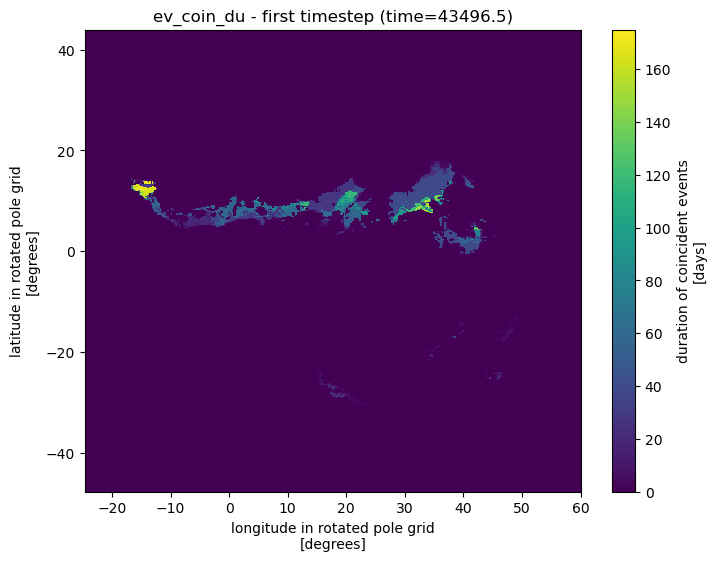

In [41]:
# Plot only the first timestep from the original dataset
da_name = 'ev_coin_du' if 'ev_coin_du' in dforg.data_vars else [v for v in dforg.data_vars if 'time' in dforg[v].dims][0]
first_timestep = dforg[da_name].isel(time=0)

plt.figure(figsize=(8, 6))
first_timestep.plot()
plt.title(f"{da_name} - first timestep (time={float(dforg.time.isel(time=0).values):.1f})")
plt.show()

In [11]:
sims_rcp26 = glob.glob(datadir+'/ENSEMBLE/ev_coin_sdu_median_'+var_pattern+'_rcp26_*'+'.nc' )
# Sort the files to ensure correct order
sims_rcp26.sort()
sims_rcp26
sims_rcp85 = glob.glob(datadir+'/ENSEMBLE/ev_coin_sdu_median_'+var_pattern+'_rcp85_*'+'.nc' )
# Sort the files to ensure correct order
sims_rcp85.sort()
sims_rcp85

['/work/ch0636/g300047/cicles/compound-events/results/ENSEMBLE/ev_coin_sdu_median_SU35_du3_DD_du5_rcp85_1991-2020.nc',
 '/work/ch0636/g300047/cicles/compound-events/results/ENSEMBLE/ev_coin_sdu_median_SU35_du3_DD_du5_rcp85_2031-2060.nc',
 '/work/ch0636/g300047/cicles/compound-events/results/ENSEMBLE/ev_coin_sdu_median_SU35_du3_DD_du5_rcp85_2069-2098.nc']

In [11]:
# plot
plot_dir='/work/ch0636/g300047/cicles/factsheet_africa/PLOTS/AFR22_compound_events'
var='ev_coin_sdu_median'
print('Selected colors, levels for plotting ', var)
color_steps, level_steps = colorsteps_absolute(var)

# mask out only country
sims_rcp26_masked, sims_rcp85_masked = maskout_country(
    sims_rcp26,
    sims_rcp85,
    shpfile_country,
    dm,
    var,
    datadir
)

Selected colors, levels for plotting  ev_coin_sdu_median
Masked files saved:
rcp26: ['/work/ch0636/g300047/cicles/compound-events/results/ENSEMBLE/masked/ev_coin_sdu_median_SU35_du3_DD_du5_rcp26_1991-2020_BF_masked.nc', '/work/ch0636/g300047/cicles/compound-events/results/ENSEMBLE/masked/ev_coin_sdu_median_SU35_du3_DD_du5_rcp26_2031-2060_BF_masked.nc', '/work/ch0636/g300047/cicles/compound-events/results/ENSEMBLE/masked/ev_coin_sdu_median_SU35_du3_DD_du5_rcp26_2069-2098_BF_masked.nc']
rcp85: ['/work/ch0636/g300047/cicles/compound-events/results/ENSEMBLE/masked/ev_coin_sdu_median_SU35_du3_DD_du5_rcp85_1991-2020_BF_masked.nc', '/work/ch0636/g300047/cicles/compound-events/results/ENSEMBLE/masked/ev_coin_sdu_median_SU35_du3_DD_du5_rcp85_2031-2060_BF_masked.nc', '/work/ch0636/g300047/cicles/compound-events/results/ENSEMBLE/masked/ev_coin_sdu_median_SU35_du3_DD_du5_rcp85_2069-2098_BF_masked.nc']


['/work/ch0636/g300047/cicles/compound-events/results/ENSEMBLE/masked/ev_coin_sdu_median_SU35_du3_DD_du5_rcp26_1991-2020_BF_masked.nc', '/work/ch0636/g300047/cicles/compound-events/results/ENSEMBLE/masked/ev_coin_sdu_median_SU35_du3_DD_du5_rcp26_2031-2060_BF_masked.nc', '/work/ch0636/g300047/cicles/compound-events/results/ENSEMBLE/masked/ev_coin_sdu_median_SU35_du3_DD_du5_rcp26_2069-2098_BF_masked.nc']
['/work/ch0636/g300047/cicles/compound-events/results/ENSEMBLE/masked/ev_coin_sdu_median_SU35_du3_DD_du5_rcp85_1991-2020_BF_masked.nc', '/work/ch0636/g300047/cicles/compound-events/results/ENSEMBLE/masked/ev_coin_sdu_median_SU35_du3_DD_du5_rcp85_2031-2060_BF_masked.nc', '/work/ch0636/g300047/cicles/compound-events/results/ENSEMBLE/masked/ev_coin_sdu_median_SU35_du3_DD_du5_rcp85_2069-2098_BF_masked.nc']
shapefile provided:
sims_rcp26 ['/work/ch0636/g300047/cicles/compound-events/results/ENSEMBLE/masked/ev_coin_sdu_median_SU35_du3_DD_du5_rcp26_1991-2020_BF_masked.nc', '/work/ch0636/g300047

'/work/ch0636/g300047/cicles/factsheet_africa/PLOTS/AFR22_compound_events/SU35_du3_DD_du5_median_absolut_Burkina_Faso_1200.png'

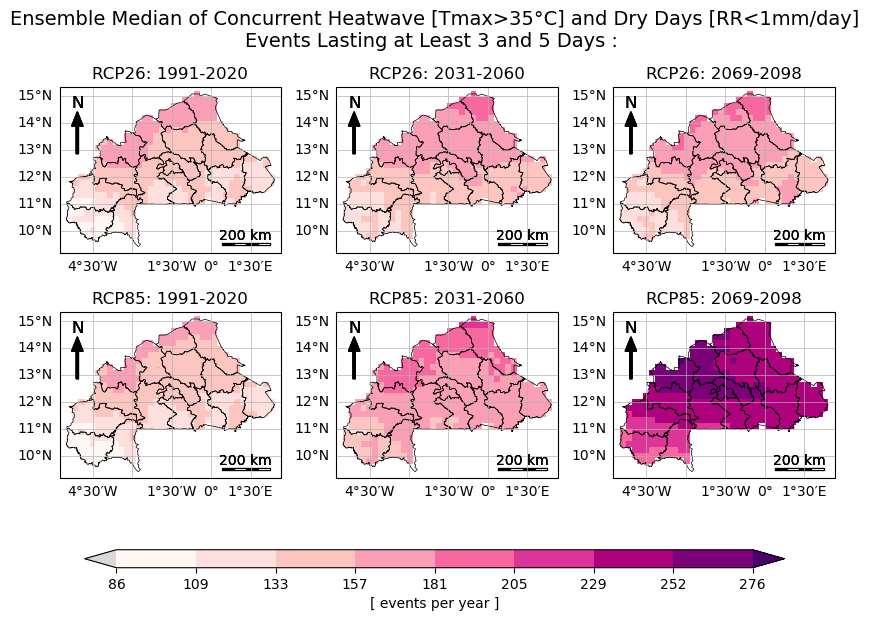

In [13]:
# Recalculate levels based on masked data
level_steps = min_max_levels(sims_rcp26_masked, sims_rcp85_masked, var)


# Now plot the absolute values
plot_absolut(
    sims_rcp26_masked,
    sims_rcp85_masked,
    level_steps, 
    color_steps,    
    plot_dir,
    title=title,
    var=var,
    westafrica=True,
    shapefile=shpfile_country,
    country=country,
    user_dpi=1200,
    rows=2, 
    columns=3,
    fancy=True,
    row_gap=-0.05,
    wspace=0.25
)

# save plot to better file name and do not over right old plots
src=os.path.join(plot_dir,'ev_coin_sdu_median_absolut_'+country+'_1200.png')
print ('src: ',src)
dst=os.path.join(plot_dir,var_pattern+'_median_absolut_'+country+'_1200.png')
print(f"Moving {src} -> {dst}")
shutil.move(src, dst)



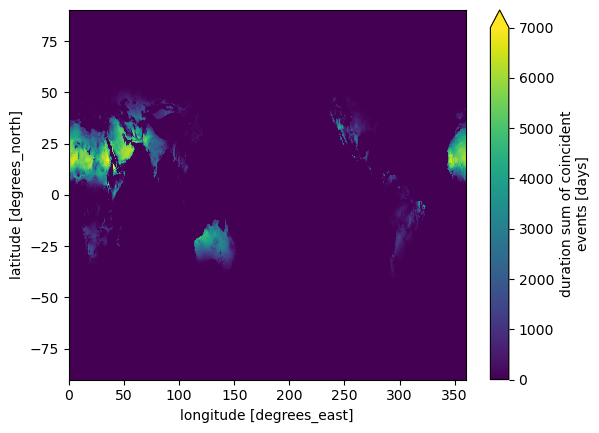

In [ ]:
# Inspect a single file and its variable 'ev_coin_sdu'
era_file='compev_SU35_du3_DD_du5_1991-2020.nc'
era_dir='/work/ch0636/g300047/cicles/compound-events/results-era5'
ds_single = xr.open_dataset(f"{era_dir}/{era_file}", decode_timedelta=False)
ev_coin_sdu = ds_single['ev_coin_sdu']
ev_coin_sdu.plot(vmin=0, vmax=7000)

plot_absolut(
    sims_rcp26_masked,
    sims_rcp85_masked,
    level_steps, 
    color_steps,    
    plot_dir,
    title=title,
    var=var,
    westafrica=True,
    shapefile=shpfile_country,
    country=country,
    user_dpi=1200,
    rows=2, 
    columns=3,
    fancy=True,
    row_gap=-0.05,
    wspace=0.25
)

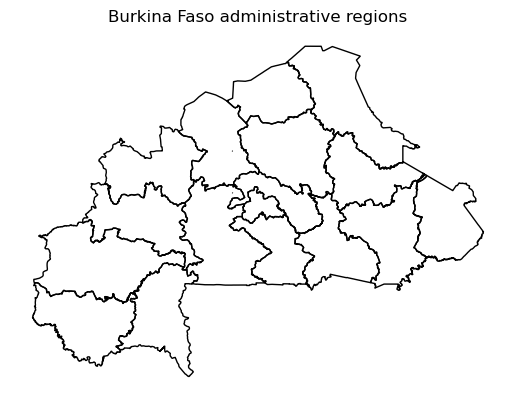

In [67]:
# Plot the preloaded Burkina Faso shapefile
ax = shpfile_BF.plot(edgecolor='black', facecolor='none')
ax.set_title('Burkina Faso administrative regions')
ax.set_axis_off()
plt.show()

In [69]:
# Add a dynamic scale bar (in km) to the existing shapefile plot (ax)

def _nice_length_km(target_km):
    # pick a nice rounded length close to 20% of map width
    candidates = [10, 25, 50, 100, 150, 200, 300, 500, 1000]
    for c in candidates:
        if c >= target_km:
            return c
    return candidates[-1]

def add_scalebar(ax, geom=None, location='lower left', segments=4, pad_frac=0.05, height_frac=0.01, font_size=10):
    # Representative latitude for km-per-degree conversion
    if geom is not None:
        lat_ref = float(geom.centroid.y)
    else:
        y0, y1 = ax.get_ylim()
        lat_ref = (y0 + y1) / 2.0

    # Approx km per degree of longitude at given latitude
    km_per_deg_lon = 111.32 * np.cos(np.deg2rad(lat_ref))

    # Determine bar length ~ 20% of map width, rounded to a nice value
    x0, x1 = ax.get_xlim()
    y0, y1 = ax.get_ylim()
    width_deg = x1 - x0
    width_km = max(1e-6, width_deg * km_per_deg_lon)
    length_km = _nice_length_km(width_km * 0.2)
    length_deg = length_km / km_per_deg_lon

    # Bar placement
    pad_x = pad_frac * width_deg
    pad_y = pad_frac * (y1 - y0)
    bar_height = height_frac * (y1 - y0)

    if location == 'lower left':
        bx0 = x0 + pad_x
        by0 = y0 + pad_y
    elif location == 'lower right':
        bx0 = x1 - pad_x - length_deg
        by0 = y0 + pad_y
    elif location == 'upper left':
        bx0 = x0 + pad_x
        by0 = y1 - pad_y - bar_height
    elif location == 'upper right':
        bx0 = x1 - pad_x - length_deg
        by0 = y1 - pad_y - bar_height
    else:
        bx0 = x0 + pad_x
        by0 = y0 + pad_y

    # Draw alternating black/white segments
    seg_width = length_deg / max(1, segments)
    for i in range(segments):
        rect = mpl.patches.Rectangle(
            (bx0 + i * seg_width, by0),
            seg_width,
            bar_height,
            facecolor=('black' if i % 2 == 0 else 'white'),
            edgecolor='black',
            linewidth=0.8
        )
        ax.add_patch(rect)

    # Label
    ax.text(
        bx0 + length_deg / 2.0,
        by0 + bar_height * 1.5,
        f'{int(length_km)} km',
        ha='center', va='bottom',
        fontsize=font_size
    )

# Compute Burkina Faso union geometry from the already loaded shapefile
union_geom = shpfile_BF.geometry.unary_union

# Use the existing ax and Burkina Faso geometry union to add a scale bar
add_scalebar(ax, geom=union_geom, location='lower left', segments=4)

/tmp/ipykernel_72054/775770534.py:74: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  union_geom = shpfile_BF.geometry.unary_union


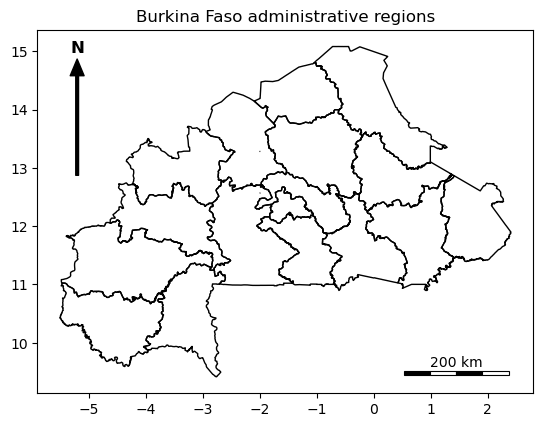

In [72]:
ax = shpfile_BF.plot(edgecolor='black', facecolor='none')
ax.set_title('Burkina Faso administrative regions')
# Add a North arrow to the existing shapefile plot (ax)
arrowprops = dict(facecolor='black', edgecolor='black', width=2, headwidth=10, headlength=12)
# Arrow pointing up in axes coordinates
ax.annotate('', xy=(0.08, 0.92), xytext=(0.08, 0.60), xycoords='axes fraction', arrowprops=arrowprops)
# Label "N" above the arrow
ax.text(0.08, 0.93, 'N', transform=ax.transAxes, ha='center', va='bottom', fontsize=12, fontweight='bold')
add_scalebar(ax, geom=union_geom, location='lower right', segments=4)
plt.show()